# Bab 5 — Model Linear dan Regularisasi

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025), Bab 5
**Sumber kode:** [PacktPublishing/Scikit-Learn-Cookbook-Third-Edition](https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition) (`Chapter_5`)
**Direproduksi dan dijelaskan oleh:** Tarannia Raisha Putri — NIM 101032300231 — S1 Teknik Komputer, Telkom University

**Resep yang dibahas**

| # | Resep | Alat utama |
|---|--------|-----------|
| 5.1 | Pengantar Model Linear | `LinearRegression`, `make_regression`, `mean_squared_error`, `r2_score` |
| 5.2 | Regresi Ridge dan Lasso | `Ridge`, `Lasso` |
| 5.3 | ElasticNet dan Regularisasi | `ElasticNet`, jalur koefisien |
| 5.4 | Regresi Polinomial (dan Interpolasi Spline) | `PolynomialFeatures`, `SplineTransformer`, `make_pipeline` |
| 5.5 | Latihan Praktis Model Linear dan Regularisasi | `Ridge`, `Lasso`, `ElasticNet` pada data sintetis baru |

> Nomor resep ditambahkan di sini untuk memudahkan navigasi; buku aslinya tidak menomori resep. Resep 5.5 memakai solusi resmi dari notebook *Exercise Solution* di repositori.

## Gambaran Umum Bab

Model linear memprediksi target sebagai jumlah berbobot dari fitur-fitur. Model ini cepat, mudah ditafsirkan, dan menjadi fondasi sebagian besar statistika dan *machine learning*. Titik lemahnya juga sudah dikenal: ketika fitur banyak, berisik, atau sangat berkorelasi, bobot hasil fitting menjadi tidak stabil dan model *overfitting*. **Regularisasi** mengatasi hal ini dengan menambahkan penalti pada besarnya bobot. Penalti *L2* (Ridge) mengecilkan semua bobot secara halus, penalti *L1* (Lasso) dapat membuat bobot tepat nol, dan ElasticNet mencampur keduanya.

Bab ini mem-fit *ordinary least squares* pada dataset sintetis yang sengaja dibuat sulit, membandingkannya dengan Ridge, Lasso, dan ElasticNet, memvisualisasikan bagaimana koefisien mengecil seiring membesarnya penalti, lalu menunjukkan bagaimana *ekspansi basis* (polinomial dan spline) memungkinkan model linear mengikuti hubungan yang melengkung. Dalam *pipeline* ML, ini adalah bab pertama yang membahas **pemodelan** *supervised* secara mendalam. Bab ini memakai gagasan pra-pemrosesan dari Bab 2 (fitur polinomial, penskalaan) dan menyiapkan dasar untuk Bab 6, tempat penalti yang sama diterapkan pada regresi logistik untuk klasifikasi.

## Persiapan

In [1]:
# Pustaka inti yang dipakai di sepanjang bab ini
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

# Satu seed global agar setiap eksekusi notebook menghasilkan angka yang sama.
# (Sel-sel buku tetap memakai nilai random_state masing-masing.)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Catat lingkungan persis yang menghasilkan output di bawah
print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")

Python       : 3.13.5
numpy        : 2.1.3
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.4


## Resep 5.1 — Pengantar Model Linear

**Tujuan.** Mem-fit regresi *ordinary least squares* (OLS) pada dataset sintetis berdimensi tinggi dengan fitur-fitur yang sangat berkorelasi, lalu mengukur seberapa baik model memprediksi data yang belum pernah dilihat.

### Teori

**Intuisi.** Regresi linear menarik permukaan datar "terbaik" (garis di 1-D, bidang atau *hyperplane* di dimensi lebih tinggi) melalui data, dengan "terbaik" berarti total kuadrat jarak vertikal antara titik dan permukaan sekecil mungkin. Setiap koefisien menyatakan seberapa besar prediksi berubah ketika fiturnya naik satu satuan *sementara semua fitur lain tetap*.

**Matematika.** Dengan $n$ sampel, $p$ fitur, matriks desain $X\in\mathbb{R}^{n\times p}$, target $\mathbf{y}\in\mathbb{R}^n$, koefisien $\boldsymbol\beta\in\mathbb{R}^p$, dan intersep $\beta_0$, modelnya adalah $\mathbf{y} = \beta_0\mathbf{1} + X\boldsymbol\beta + \boldsymbol\varepsilon$, dengan $\boldsymbol\varepsilon$ adalah *noise* acak. OLS meminimalkan jumlah kuadrat residual
$$\mathrm{RSS}(\boldsymbol\beta)=\lVert\mathbf{y}-\beta_0\mathbf{1}-X\boldsymbol\beta\rVert_2^2,$$
yang (setelah pemusatan) memiliki solusi bentuk tertutup $\hat{\boldsymbol\beta}=(X^\top X)^{-1}X^\top\mathbf{y}$. Jika *noise* memiliki variansi $\sigma^2$, maka $\mathrm{Var}(\hat{\boldsymbol\beta})=\sigma^2(X^\top X)^{-1}$. Ketika fitur hampir kolinear, $X^\top X$ mendekati singular, inversnya memiliki entri yang sangat besar, dan koefisien menjadi sangat tidak stabil. Dua metrik mengevaluasi prediksi $\hat y_i$:
$$\mathrm{MSE}=\frac1n\sum_i(y_i-\hat y_i)^2,\qquad R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$
MSE berada dalam satuan target kuadrat. $R^2$ tidak bersatuan: 1 berarti fit sempurna, 0 berarti tidak lebih baik daripada selalu memprediksi $\bar y$, dan nilainya bisa negatif pada data uji.

**Cara scikit-learn mengimplementasikannya.** `LinearRegression(fit_intercept=True, copy_X=True, n_jobs=None, positive=False)`. `fit` memusatkan data dan menyelesaikan masalah *least squares* dengan `scipy.linalg.lstsq` (solver berbasis SVD yang juga mampu menangani $X$ yang rank-nya tidak penuh), lalu menyimpan `coef_` dan `intercept_`. `predict` mengembalikan $\beta_0 + X\boldsymbol\beta$. `score` mengembalikan $R^2$. Tidak ada hiperparameter yang perlu di-*tuning*.

**Asumsi, kelebihan, keterbatasan.**

* Mengasumsikan hubungan linear dan galat yang saling independen. Variansi galat yang konstan dan galat berdistribusi normal terutama penting untuk selang kepercayaan.
* Tanpa regularisasi: dengan banyak fitur dibanding sampel, atau dengan fitur yang berkorelasi, OLS *overfitting* dan koefisiennya bisa sangat besar dengan tanda yang saling meniadakan.
* Kelebihan: bentuk tertutup, cepat, mudah ditafsirkan, dan merupakan *baseline* yang penting.
* Gunakan ketika fitur sedikit dan tidak sangat kolinear. Jika tidak, pilih versi yang teregularisasi.

### Kode

Buku membangun dataset yang sengaja sulit dalam beberapa langkah: 1.000 sampel dengan 100 fitur yang 10 di antaranya informatif, lalu **menimpa fitur 50–99** dengan salinan berisik dari fitur 0–49 untuk menciptakan multikolinearitas, mengalikan target dengan 1.000, dan menambahkan suku non-linear kecil berbasis `feature_0`.

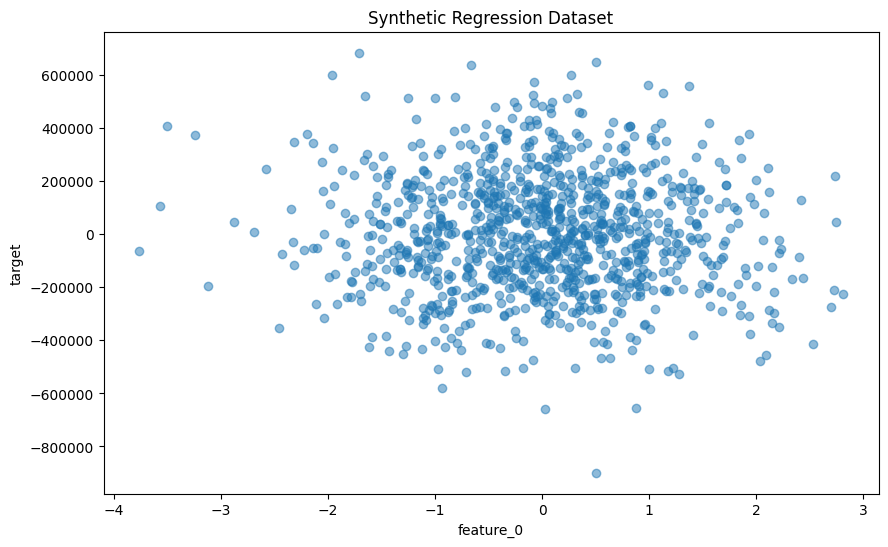

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression

# 1.000 sampel, 100 fitur, hanya 10 yang memengaruhi target
X, y = make_regression(n_samples=1000,
                      n_features=100,
                      n_informative=10,
                      noise=20,
                      random_state=123)

# Timpa fitur 50-99 dengan salinan berisik fitur 0-49 (kolinearitas kuat)
for i in range(50, 100):
    X[:, i] = X[:, i-50] + np.random.normal(0, 0.1, size=1000)

feature_names = [f'feature_{i}' for i in range(100)]

# feature_0 dipakai untuk plot 2-D
X_plot = X[:, 0].reshape(-1, 1)

# Skalakan ulang target dan tambahkan suku non-linear kecil dalam feature_0
y = y * 1000
y = y + np.sin(X_plot.ravel()) * 150 + np.exp(X_plot.ravel()/10)

# Salinan dalam bentuk tabel agar mudah dipakai
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y
df_plot = pd.DataFrame({'feature_0': X_plot.ravel(), 'target': y})

# Target terhadap satu fitur
plt.figure(figsize=(10, 6))
plt.scatter(X_plot, y, alpha=0.5)
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Synthetic Regression Dataset')
plt.show()

In [3]:
# Fitur mana yang informatif? make_regression dapat mengembalikan koefisien sebenarnya (tambahan)
_, _, true_coef = make_regression(n_samples=1000, n_features=100, n_informative=10,
                                  noise=20, random_state=123, coef=True)
informative = np.flatnonzero(true_coef)
overwritten = informative[informative >= 50]
share = (true_coef[overwritten] ** 2).sum() / (true_coef ** 2).sum()
print("indeks fitur informatif:", informative)
print("di antaranya, yang ditimpa oleh loop kolinearitas:", overwritten)
print(f"porsi variansi sinyal yang dibawa fitur yang ditimpa: {share:.1%}")
print("corr(feature_0, feature_50) =", round(np.corrcoef(X[:, 0], X[:, 50])[0, 1], 4))
print("simpangan baku target =", round(y.std()))

indeks fitur informatif: [ 3 21 25 66 68 71 75 81 98 99]
di antaranya, yang ditimpa oleh loop kolinearitas: [66 68 71 75 81 98 99]
porsi variansi sinyal yang dibawa fitur yang ditimpa: 78.5%
corr(feature_0, feature_50) = 0.9954
simpangan baku target = 223821


**Interpretasi output.**

* Plot sebar **tidak menunjukkan hubungan yang terlihat** antara `feature_0` dan target: awan bulat dengan target tersebar kira-kira ±600.000. Ini wajar, karena `feature_0` bukan salah satu fitur informatif. Suku `sin` dan `exp` paling banyak menambah sekitar ±150 pada target dengan simpangan baku ≈ 223.821, sehingga "non-linearitas" tidak terlihat pada skala ini.
* Pengecekan tambahan mengungkap efek samping penting dari konstruksi buku. `make_regression` menyebar 10 fitur informatif di kolom `[3, 21, 25, 66, 68, 71, 75, 81, 98, 99]`. Loop kolinearitas kemudian **menimpa 7 di antaranya** (66, 68, 71, 75, 81, 98, 99) dengan salinan kolom yang tidak informatif. Ketujuh fitur itu membawa **≈ 78,5 %** variansi sinyal, dan informasi tersebut kini hilang dari `X`, padahal `y` masih bergantung padanya.
* Akibatnya, bahkan model linear sempurna paling banyak hanya dapat menjelaskan sekitar 21 % variansi target. Ingat batas atas ini saat membaca nilai $R^2$ yang rendah di bawah. Kolinearitasnya sendiri nyata: `feature_0` dan `feature_50` berkorelasi 0.9954.

Mean Squared Error: 47193190931.31
R-squared: 0.05


/Users/taraanrp/Telkom/Machine Learning/Scikit-learn Cookbook (O’Reilly)./.venv/lib/python3.13/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


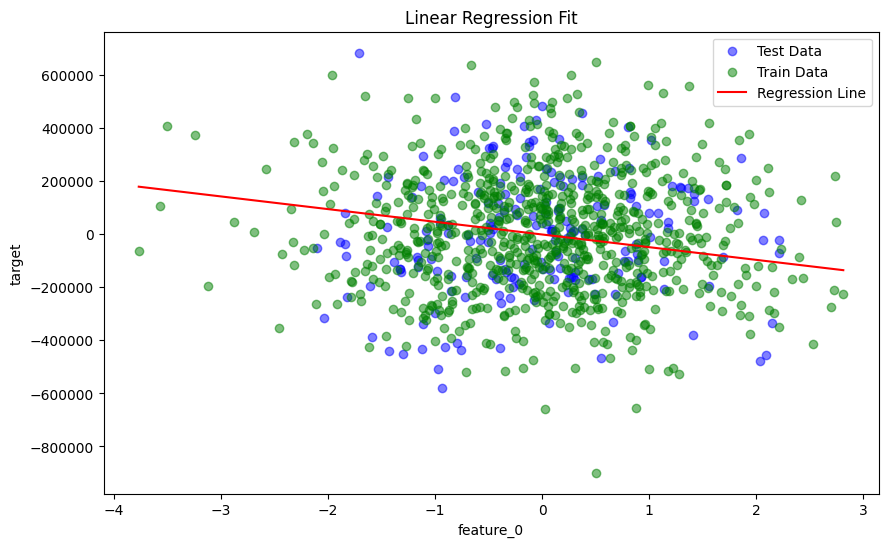

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Pembagian 80/20 -> 800 sampel latih / 200 sampel uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

# Ordinary least squares pada ke-100 fitur
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

# Metrik galat pada data uji
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f'Mean Squared Error: {mse:.2f}')
print(f'R-squared: {r2:.2f}')

# Plot data terhadap feature_0 beserta garis prediksi model
plt.figure(figsize=(10, 6))
plt.scatter(X_test[:, 0], y_test, color='blue', alpha=0.5, label='Test Data')
plt.scatter(X_train[:, 0], y_train, color='green', alpha=0.5, label='Train Data')

# Garis prediksi: variasikan feature_0, tahan 99 fitur lainnya di 0
X_line = np.linspace(df['feature_0'].min(), df['feature_0'].max(), 100).reshape(-1, 1)
X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()
y_line = linear_model.predict(pd.DataFrame(X_line_full, columns=feature_names))

plt.plot(X_line, y_line, color='red', label='Regression Line')
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Linear Regression Fit')
plt.legend()
plt.show()

> **Catatan:** `UserWarning: X has feature names, but LinearRegression was fitted without feature names` berasal dari kode buku. Model di-fit pada array NumPy, tetapi garisnya diprediksi dari sebuah `DataFrame`. Urutan kolomnya identik, sehingga prediksinya benar dan peringatan ini tidak berbahaya. Peringatan dibiarkan agar kode tidak berubah.

In [5]:
# R^2 latih vs uji serta koefisien feature_0 / feature_50 (tambahan)
print("R^2 latih:", round(linear_model.score(X_train, y_train), 3), "| R^2 uji:", round(r2, 3))
print("koef feature_0  :", round(linear_model.coef_[0]))
print("koef feature_50 :", round(linear_model.coef_[50]))
print("|koef| terbesar :", round(np.abs(linear_model.coef_).max()))

R^2 latih: 0.356 | R^2 uji: 0.052
koef feature_0  : -47734
koef feature_50 : 36799
|koef| terbesar : 201079


**Interpretasi output.**

* OLS mencapai **MSE uji sekitar 4,72 × 10¹⁰** (RMSE ≈ 217.000, kira-kira sebesar simpangan baku target itu sendiri) dan **$R^2 = 0.05$**. Model hanya menjelaskan 5 % variansi data uji.
* Pengecekan tambahan menunjukkan **$R^2$ latih 0.356 vs $R^2$ uji 0.052**: *overfitting* yang jelas. Dengan 100 koefisien, 800 sampel, dan 50 pasangan fitur yang hampir kembar, OLS mem-fit *noise* di data latih yang tidak terbawa ke data uji.
* Koefisiennya mengilustrasikan masalah variansi dari bagian teori: koefisien terbesar bermagnitudo ≈ 201.000, dan pasangan hampir kembar `feature_0`/`feature_50` menerima koefisien besar dengan **tanda berlawanan** yang sebagian besar saling meniadakan.
* Garis merah adalah prediksi model ketika hanya `feature_0` yang bervariasi dan 99 fitur lainnya ditahan di 0. Kemiringannya hanyalah `coef_[0]`. Karena `feature_50` hampir merupakan salinan `feature_0`, menahan satu fitur sambil menggerakkan yang lain adalah situasi yang tidak pernah terjadi di data, sehingga garis ini tidak boleh dibaca sebagai "efek `feature_0`".

### Poin Penting
* OLS meminimalkan galat kuadrat dalam bentuk tertutup. Estimatornya tidak bias, tetapi variansinya meledak ketika fitur banyak atau kolinear.
* Di sini OLS *overfitting* ($R^2$ latih 0.356 vs uji 0.052), dan fitur yang hampir kembar mendapat koefisien besar yang saling meniadakan.
* Loop kolinearitas buku menimpa 7 dari 10 fitur informatif, sehingga $R^2$ yang dapat dicapai terbatas sekitar 0,21. Selalu periksa cara dataset sintetis dibangun sebelum menilai model berdasarkan dataset itu.

## Resep 5.2 — Regresi Ridge dan Lasso

**Tujuan.** Mengurangi *overfitting* pada dataset yang sama dengan memberi penalti pada koefisien yang besar, memakai penalti L2 (Ridge) dan penalti L1 (Lasso), lalu membandingkan keduanya dengan OLS biasa.

### Teori

**Intuisi.** Regularisasi menambahkan "harga" untuk koefisien yang besar. Model kemudian menerima galat latih yang sedikit lebih buruk demi bobot yang lebih kecil dan lebih stabil, yang biasanya lebih baik dalam generalisasi. Inilah *trade-off bias–variansi*: sedikit bias, jauh lebih sedikit variansi. **Ridge** mengenakan harga berdasarkan kuadrat besarnya bobot dan mengecilkan semuanya secara halus ke arah nol. **Lasso** mengenakan harga berdasarkan nilai mutlaknya, yang mendorong sebagian bobot menjadi *tepat* nol, sehingga Lasso juga melakukan seleksi fitur.

**Matematika.**

* **Ridge (L2):** $\displaystyle\hat{\boldsymbol\beta}^{\text{ridge}}=\arg\min_{\boldsymbol\beta}\;\lVert\mathbf{y}-X\boldsymbol\beta\rVert_2^2+\alpha\lVert\boldsymbol\beta\rVert_2^2$, dengan bentuk tertutup $(X^\top X+\alpha I)^{-1}X^\top\mathbf{y}$. Penambahan $\alpha I$ membuat matriks dapat diinvers dan terkondisi baik bahkan pada kolinearitas sempurna.
* **Lasso (L1):** $\displaystyle\hat{\boldsymbol\beta}^{\text{lasso}}=\arg\min_{\boldsymbol\beta}\;\frac{1}{2n}\lVert\mathbf{y}-X\boldsymbol\beta\rVert_2^2+\alpha\lVert\boldsymbol\beta\rVert_1$, dengan $\lVert\boldsymbol\beta\rVert_1=\sum_j|\beta_j|$. Tidak ada bentuk tertutup. Optimum dicari dengan *coordinate descent*, dengan setiap pembaruan berupa langkah *soft-thresholding* $\beta_j\leftarrow \mathrm{sign}(z_j)\max(|z_j|-\alpha,0)$ (untuk fitur terstandardisasi). Setiap koefisien yang korelasi parsialnya $z_j$ dengan residual lebih kecil dari $\alpha$ menjadi tepat 0.
* $\alpha\ge0$ adalah kekuatan regularisasi: $\alpha=0$ mengembalikan OLS, dan $\alpha\to\infty$ mendorong semua koefisien ke 0. Secara geometris, daerah kendala L2 berbentuk bola dan daerah L1 berbentuk belah ketupat yang sudut-sudutnya terletak di sumbu, itulah sebabnya solusi L1 cenderung jarang (*sparse*).

**Cara scikit-learn mengimplementasikannya.**

* `Ridge(alpha=1.0, fit_intercept=True, solver="auto")` meminimalkan galat kuadrat *tanpa normalisasi* di atas. `solver="auto"` memilih solver Cholesky, SVD, sparse-CG, … berdasarkan data.
* `Lasso(alpha=1.0, max_iter=1000, tol=1e-4, selection="cyclic")` meminimalkan *loss* yang dinormalisasi $\frac{1}{2n}$ dengan *coordinate descent* dan memunculkan `ConvergenceWarning` jika `tol` tidak tercapai dalam `max_iter`. Resep ini memakai `alpha=10.0, max_iter=10000, tol=0.001`.
* Karena kedua *loss* diskalakan secara berbeda, **`alpha` yang sama tidak berarti kekuatan yang sama** untuk `Ridge` dan `Lasso`. Penalti juga bergantung pada skala fitur, sehingga fitur sebaiknya distandardisasi (di sini fitur sudah kira-kira $\mathcal{N}(0,1)$). Intersep tidak pernah diberi penalti.

**Asumsi, kelebihan, keterbatasan.**

* Ridge menangani kolinearitas dengan baik: fitur yang berkorelasi berbagi bobot. Ridge tidak pernah membuang fitur.
* Lasso menghasilkan model yang *sparse* dan mudah ditafsirkan, tetapi cenderung memilih satu fitur dari kelompok yang berkorelasi secara sembarang dan bisa tidak stabil ketika $p\gg n$.
* `alpha` harus di-*tuning* (misalnya `RidgeCV`, `LassoCV`). Tidak ada penalti yang bisa memperbaiki model yang salah spesifikasi atau informasi yang hilang.

### Kode

In [6]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

# Regresi dengan penalti L2; alpha mengatur kekuatan penalti
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

# Regresi dengan penalti L1 dan anggaran iterasi lebih besar agar konvergen
lasso_model = Lasso(alpha=10.0, max_iter=10000, tol=0.001)
lasso_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

# Prediksi OLS dari Resep 5.1 sebagai pembanding
y_pred_linear = linear_model.predict(X_test)

# Kumpulkan metrik uji ketiga model
metrics = {
    'Model': ['Ridge Regression', 'Lasso Regression', 'Linear Regression'],
    'Mean Squared Error': [
        mean_squared_error(y_test, y_pred_ridge),
        mean_squared_error(y_test, y_pred_lasso),
        mean_squared_error(y_test, y_pred_linear)
    ],
    'R-squared': [
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso),
        r2_score(y_test, y_pred_linear)
    ]
}

# Terbaik (MSE terendah) di atas, diformat sebagai string untuk tampilan
metrics_df = pd.DataFrame(metrics)
metrics_df = metrics_df.sort_values('Mean Squared Error', ascending=True)

metrics_df['Mean Squared Error'] = metrics_df['Mean Squared Error'].map('{:.2f}'.format)
metrics_df['R-squared'] = metrics_df['R-squared'].map('{:.2f}'.format)

display(metrics_df)

,Model,Mean Squared Error,R-squared
0,Ridge Regression,45541631136.95,0.09
1,Lasso Regression,47033381479.46,0.06
2,Linear Regression,47193190931.31,0.05


/Users/taraanrp/Telkom/Machine Learning/Scikit-learn Cookbook (O’Reilly)./.venv/lib/python3.13/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but Ridge was fitted without feature names
  warnings.warn(
/Users/taraanrp/Telkom/Machine Learning/Scikit-learn Cookbook (O’Reilly)./.venv/lib/python3.13/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but Lasso was fitted without feature names
  warnings.warn(
/Users/taraanrp/Telkom/Machine Learning/Scikit-learn Cookbook (O’Reilly)./.venv/lib/python3.13/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


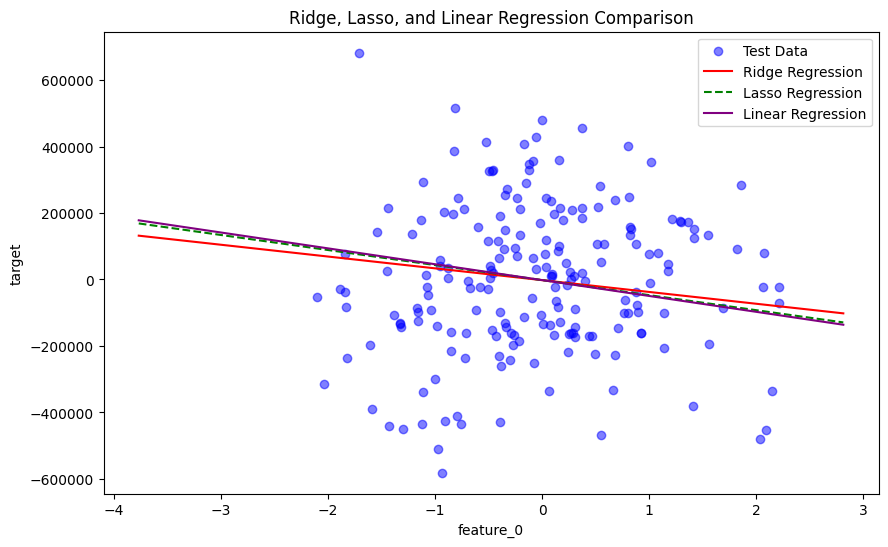

In [7]:
# Garis prediksi di sepanjang feature_0 untuk ketiga model
plt.figure(figsize=(10, 6))
plt.scatter(X_test[:, 0], y_test, color='blue', alpha=0.5, label='Test Data')

# Variasikan feature_0 saja, fitur lain tetap di 0
X_line = np.linspace(df['feature_0'].min(), df['feature_0'].max(), 100).reshape(-1, 1)
X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()
X_line_df = pd.DataFrame(X_line_full, columns=feature_names)

y_line_ridge = ridge_model.predict(X_line_df)
y_line_lasso = lasso_model.predict(X_line_df)
y_line_linear = linear_model.predict(X_line_df)

plt.plot(X_line, y_line_ridge, color='red', label='Ridge Regression')
plt.plot(X_line, y_line_lasso, color='green', linestyle='--', label='Lasso Regression')
plt.plot(X_line, y_line_linear, color='purple', label='Linear Regression')
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Ridge, Lasso, and Linear Regression Comparison')
plt.legend()
plt.show()

**Interpretasi output.**

* **Ridge adalah yang terbaik** (MSE ≈ 4,55 × 10¹⁰, $R^2 = 0.09$), Lasso berikutnya (4,70 × 10¹⁰, $R^2 = 0.06$), dan OLS terakhir (4,72 × 10¹⁰, $R^2 = 0.05$). Kedua penalti membantu, tetapi hanya sedikit, karena keterbatasan utamanya (fitur informatif yang hilang) tidak dapat diperbaiki oleh penalti apa pun.
* Ridge lebih membantu daripada Lasso di sini. Dengan 50 pasangan hampir kembar, penalti L2 memungkinkan setiap pasangan *berbagi* bobot, yang langsung mengurangi masalah koefisien saling meniadakan yang terlihat di Resep 5.1.
* `Lasso(alpha=10)` sangat lemah pada skala ini: target memiliki simpangan baku sekitar 224.000, sehingga penalti 10 per satuan koefisien hampir tidak berarti. Garis Lasso hampir menimpa garis OLS, dan pengecekan tambahan di Resep 5.3 menunjukkan Lasso masih mempertahankan 97 dari 100 koefisien.
* Garis Ridge lebih landai, menunjukkan bahwa koefisien `feature_0`-nya telah dikecilkan.

### Poin Penting
* Ridge menambahkan $\alpha\lVert\boldsymbol\beta\rVert_2^2$ (pengecilan halus, menstabilkan fitur yang kolinear). Lasso menambahkan $\alpha\lVert\boldsymbol\beta\rVert_1$ (pengecilan ditambah nol yang tepat).
* Ridge memberi $R^2$ uji terbaik (0.09) di antara ketiganya, karena kolinearitas adalah masalah yang memang menjadi sasaran desainnya.
* `alpha` bergantung pada skala dan tidak dapat dibandingkan antara `Ridge` dan `Lasso`. *Tuning* dengan *cross-validation*, jangan memilih angka bulat begitu saja.

## Resep 5.3 — ElasticNet dan Regularisasi

**Tujuan.** Menggabungkan penalti L1 dan L2 dengan ElasticNet, memvisualisasikan bagaimana setiap koefisien mengecil seiring membesarnya penalti (jalur koefisien) untuk beberapa campuran L1/L2, dan menambahkan model ElasticNet seimbang ke tabel perbandingan.

### Teori

**Intuisi.** Sifat *sparse* Lasso menarik, tetapi pada kelompok fitur yang berkorelasi Lasso memilih satu fitur secara agak sembarang. Ridge menjaga kelompok tetap bersama tetapi tidak pernah membuang apa pun. ElasticNet memadukan keduanya: bagian L2 membuat fitur berkorelasi berbagi bobot (*grouping effect*), sedangkan bagian L1 tetap membuat fitur yang jelas tidak berguna menjadi nol.

**Matematika.** ElasticNet di scikit-learn meminimalkan
$$\frac{1}{2n}\lVert\mathbf{y}-X\boldsymbol\beta\rVert_2^2+\alpha\,\rho\,\lVert\boldsymbol\beta\rVert_1+\frac{\alpha(1-\rho)}{2}\lVert\boldsymbol\beta\rVert_2^2,$$
dengan $\alpha\ge0$ kekuatan keseluruhan dan $\rho\in[0,1]$ adalah `l1_ratio`: $\rho=1$ menghasilkan Lasso dan $\rho=0$ Ridge (yang diskalakan ulang). **Jalur koefisien** memplot setiap $\hat\beta_j(\alpha)$ seiring bertambahnya $\alpha$. Semua jalur dimulai dekat solusi *least squares* (yang tidak stabil) untuk $\alpha$ kecil dan mengecil ke 0 untuk $\alpha$ besar, dan dengan $\rho>0$ sebagian di antaranya mencapai tepat nol di sepanjang jalan.

**Cara scikit-learn mengimplementasikannya.** `ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=1000, tol=1e-4, selection="cyclic", random_state=None)` di-fit dengan *coordinate descent* seperti `Lasso`. `random_state` hanya berpengaruh jika `selection="random"`, sehingga `random_state=123` di resep ini tidak berpengaruh dengan pembaruan siklik default. `enet_path`/`ElasticNetCV` menghitung seluruh jalur secara efisien dengan *warm start*. Resep ini justru melakukan perulangan atas grid 7 alpha × 5 l1_ratio (35 kali fitting terpisah).

**Asumsi, kelebihan, keterbatasan.**

* Paling cocok untuk data berdimensi tinggi dengan kelompok fitur yang berkorelasi, persis seperti desain dataset ini.
* Ada dua hiperparameter yang perlu di-*tuning* ($\alpha$, $\rho$), idealnya bersama-sama dengan `ElasticNetCV`.
* Seperti Ridge dan Lasso, ElasticNet sensitif terhadap skala dan tidak dapat memulihkan informasi yang hilang dari $X$.

### Kode

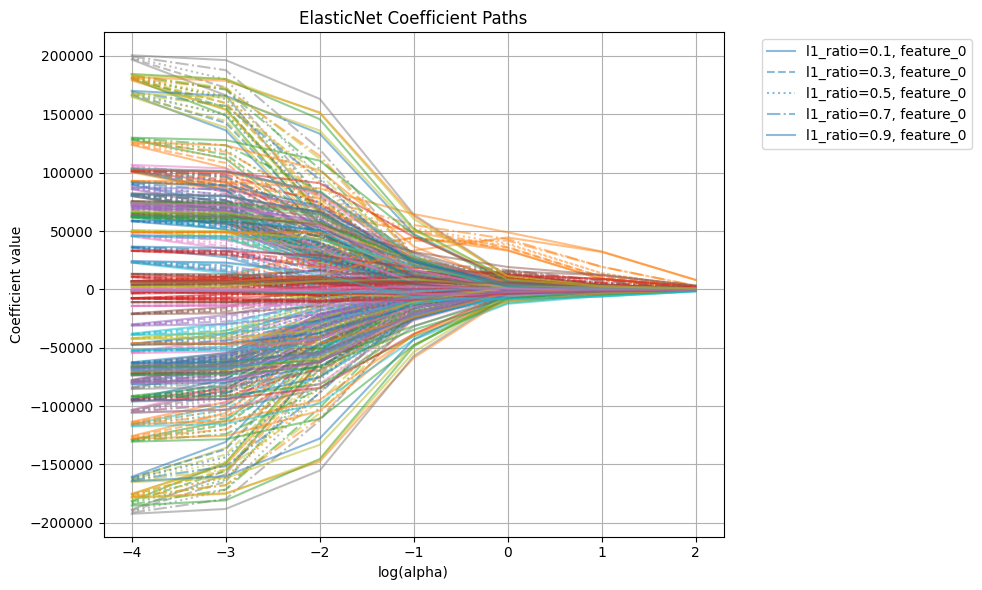

In [8]:
from sklearn.linear_model import ElasticNet

# Grid kekuatan penalti dan campuran L1/L2
alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]

coef_paths = []
labels = []

plt.figure(figsize=(10, 6))

for l1_ratio in l1_ratios:
    coefs = []
    for alpha in alphas:
        # Satu fit per (alpha, l1_ratio); simpan 100 koefisiennya
        elastic_model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=123,
                                 max_iter=10000, tol=1e-4)
        elastic_model.fit(X_train, y_train)
        coefs.append(elastic_model.coef_)

    coef_paths.append(np.array(coefs))

    # Satu garis per fitur; gaya garis menandai l1_ratio
    for feature_idx in range(X_train.shape[1]):
        plt.plot(np.log10(alphas),
                np.array(coefs)[:, feature_idx],
                label=f'l1_ratio={l1_ratio}, feature_{feature_idx}' if feature_idx == 0 else "",
                alpha=0.5,
                linestyle=['solid', 'dashed', 'dotted', 'dashdot', '-'][l1_ratios.index(l1_ratio)])

plt.xlabel('log(alpha)')
plt.ylabel('Coefficient value')
plt.title('ElasticNet Coefficient Paths')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

**Interpretasi output.** Setiap dari 500 garis adalah satu koefisien (100 fitur × 5 nilai `l1_ratio`) yang ditelusuri atas $\log_{10}\alpha\in[-4,2]$.

* Di sisi kiri ($\alpha=10^{-4}$), koefisien tersebar kira-kira **±200.000**. Ini adalah nilai-nilai tidak stabil yang saling meniadakan dari pasangan fitur hampir kembar, pada dasarnya solusi OLS.
* Antara $\log_{10}\alpha=-3$ dan $0$, kipas garis **runtuh ke arah nol**, dan pada $\alpha=1$ sebagian besar koefisien berada dalam beberapa puluh ribu dari 0. Pada $\alpha=100$, hampir semua garis berada di atau dekat 0, hanya tersisa beberapa koefisien positif kecil.
* Garis dengan `l1_ratio` lebih tinggi (lebih mirip Lasso) mencapai nol lebih cepat. Dengan $\rho=0.1$ (sebagian besar Ridge), koefisien mengecil secara halus tetapi tetap tidak nol.
* Legenda menampilkan satu entri per `l1_ratio` karena buku hanya melabeli `feature_0` dari setiap kelompok.

In [9]:
# ElasticNet seimbang: alpha moderat, campuran L1/L2 setara
elastic_model = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=123,
                          max_iter=10000, tol=1e-4)
elastic_model.fit(X_train, y_train)

elastic_pred = elastic_model.predict(X_test)
elastic_mse = mean_squared_error(y_test, elastic_pred)
elastic_r2 = r2_score(y_test, elastic_pred)

new_row = pd.DataFrame({
    'Model': ['ElasticNet Regression'],
    'Mean Squared Error': [elastic_mse],
    'R-squared': [elastic_r2]
})

# Buang baris ElasticNet sebelumnya (agar sel aman dijalankan ulang)
metrics_df = metrics_df[~metrics_df['Model'].str.contains('ElasticNet')]

# Tabel berisi string terformat, jadi ubah kembali ke float sebelum diurutkan
metrics_df['Mean Squared Error'] = metrics_df['Mean Squared Error'].astype(float)
metrics_df['R-squared'] = metrics_df['R-squared'].astype(float)

metrics_df = pd.concat([metrics_df, new_row], ignore_index=True)

metrics_df = metrics_df.sort_values('Mean Squared Error', ascending=True)

metrics_df['Mean Squared Error'] = metrics_df['Mean Squared Error'].map('{:.2f}'.format)
metrics_df['R-squared'] = metrics_df['R-squared'].map('{:.2f}'.format)

display(metrics_df)

,Model,Mean Squared Error,R-squared
3,ElasticNet Regression,42397228204.58,0.15
0,Ridge Regression,45541631136.95,0.09
1,Lasso Regression,47033381479.46,0.06
2,Linear Regression,47193190931.31,0.05


In [10]:
# Seberapa kuat setiap model mengecilkan koefisiennya? (tambahan)
models = {"Linear": linear_model, "Ridge": ridge_model, "Lasso": lasso_model, "ElasticNet": elastic_model}
pd.DataFrame({
    name: {"koef tak-nol": int((m.coef_ != 0).sum()),
           "norma L2 koef": round(float(np.linalg.norm(m.coef_))),
           "|koef| maks": round(float(np.abs(m.coef_).max())),
           "R^2 latih": round(m.score(X_train, y_train), 3),
           "R^2 uji": round(m.score(X_test, y_test), 3)}
    for name, m in models.items()
}).T

,koef tak-nol,norma L2 koef,|koef| maks,R^2 latih,R^2 uji
Linear,100.0,896661.0,201079.0,0.356,0.052
Ridge,100.0,698789.0,156073.0,0.353,0.085
Lasso,97.0,878492.0,198481.0,0.356,0.055
ElasticNet,100.0,67035.0,39321.0,0.274,0.148


**Interpretasi output.**

* ElasticNet seimbang ($\alpha=1$, $\rho=0.5$) adalah **model terbaik di bab ini untuk data ini**: MSE ≈ 4,24 × 10¹⁰ dan **$R^2 = 0.15$**, di atas Ridge (0.09), Lasso (0.06), dan OLS (0.05).
* Tabel tambahan menunjukkan alasannya. ElasticNet mengecilkan vektor koefisien sekitar **13× lebih kuat** dibanding OLS (norma L2 ≈ 67.000 vs ≈ 897.000, koefisien terbesar ≈ 39.000 vs ≈ 201.000). $R^2$ latihnya turun (0.274 vs 0.356) sementara $R^2$ ujinya naik (0.148 vs 0.052). Itulah *trade-off* bias–variansi dalam praktik: *overfitting* berkurang, generalisasi membaik.
* Lasso dengan `alpha=10` jauh lebih lemah. Ia mempertahankan **97 dari 100** koefisien dan hampir tidak mengubah solusi. ElasticNet mempertahankan ke-100 koefisien tetap tidak nol (bagian L1 dengan $\alpha\rho=0.5$ terlalu kecil untuk membuat satu pun menjadi nol), tetapi mengecilkannya dengan kuat melalui penalti gabungan.
* Bahkan $R^2$ terbaik 0.15 masih di bawah batas atas ≈ 0,21 yang diidentifikasi di Resep 5.1.

### Poin Penting
* Penalti ElasticNet $\alpha\rho\lVert\boldsymbol\beta\rVert_1+\tfrac{\alpha(1-\rho)}{2}\lVert\boldsymbol\beta\rVert_2^2$ berada di antara Lasso dan Ridge.
* Jalur koefisien menunjukkan perpindahan dari bobot tidak stabil mirip OLS (±200.000) ke bobot mendekati nol seiring bertambahnya $\alpha$.
* Pada data kolinear ini, ElasticNet($\alpha=1$, $\rho=0.5$) memiliki generalisasi terbaik ($R^2$ 0.15) dengan menukar kecocokan latih demi koefisien yang jauh lebih kecil.

## Resep 5.4 — Regresi Polinomial (dan Interpolasi Spline)

**Tujuan.** Mem-fit hubungan 1-D yang jelas non-linear (garis ditambah gelombang sinus) dengan model linear melalui ekspansi input menjadi suku polinomial atau fungsi basis spline, lalu membandingkan seberapa fleksibel setiap ekspansi perlu dibuat.

### Teori

**Intuisi.** Sebuah model dapat *linear dalam parameternya* sambil *non-linear dalam inputnya*. Ganti $x$ dengan fitur baru seperti $x, x^2, x^3,\dots$ dan *ordinary least squares* dapat mem-fit kurva. Polinomial bersifat global: mengubah fit di satu wilayah menggesernya di mana-mana, dan derajat tinggi berosilasi di tepi. **Spline** justru merekatkan potongan-potongan polinomial berderajat rendah di titik-titik yang disebut *knot*, sehingga setiap potongan hanya memengaruhi lingkungannya sendiri.

**Matematika.**

* **Regresi polinomial berderajat $d$:** $\hat y = \beta_0+\beta_1x+\beta_2x^2+\dots+\beta_dx^d$, yaitu OLS pada vektor fitur hasil ekspansi $\phi(x)=(1,x,\dots,x^d)$.
* **Spline kubik dengan knot $t_1<\dots<t_K$:** fungsi yang berupa polinomial kubik di setiap interval $[t_k,t_{k+1}]$ serta memiliki nilai, turunan pertama, dan turunan kedua yang kontinu di setiap knot. Fungsi ini dapat ditulis sebagai $\hat y=\sum_{m=1}^{M}\beta_m B_m(x)$, dengan $B_m$ adalah **fungsi basis B-spline**. Masing-masing hanya bernilai tidak nol di beberapa interval yang berdekatan (*local support*). Untuk derajat $q$ dan $K$ knot terdapat $M=K+q-1$ fungsi basis.

Target di sini adalah $y = 2x + 27\sin(x/8) + \varepsilon$ dengan $\varepsilon\sim\mathcal{N}(0,4^2)$. Baik $2x$ maupun $\sin(x/8)$ adalah **fungsi ganjil** ($f(-x)=-f(x)$), sehingga pangkat genap $x^2, x^4$ hampir tidak membawa sinyal yang berguna. Kita dapat mengharapkan derajat 2 ≈ derajat 1 dan derajat 4 ≈ derajat 3.

**Cara scikit-learn mengimplementasikannya.**

* `PolynomialFeatures(degree=2, include_bias=True)` membuat pangkat-pangkat tersebut (dan, untuk beberapa input, interaksinya). `LinearRegression` kemudian mem-fit-nya.
* `SplineTransformer(n_knots=5, degree=3, knots="uniform", extrapolation="constant", include_bias=True)`: `fit` menempatkan `n_knots` knot berjarak sama di rentang data latih, dan `transform` mengevaluasi basis B-spline, menghasilkan `n_knots + degree - 1` kolom.
* `make_pipeline(spline, LinearRegression())` merangkai kedua langkah tanpa memberi nama (nama diturunkan dari nama kelas).

**Asumsi, kelebihan, keterbatasan.**

* Polinomial: sederhana, tetapi terkondisi buruk secara numerik untuk $|x|$ besar (di sini $x^5$ mencapai $50^5\approx3\times10^8$) dan cenderung berperilaku liar di batas (fenomena Runge). Jaga derajat tetap rendah dan skalakan input.
* Spline: fleksibel dan stabil berkat *local support*. Jumlah dan penempatan knot mengendalikan *trade-off* bias–variansi, sehingga knot yang terlalu banyak menyebabkan *overfitting*.
* Keduanya adalah ekspansi basis, sehingga dengan banyak fitur input jumlah kolom meledak dan regularisasi (Resep 5.2–5.3) menjadi perlu.

### Kode

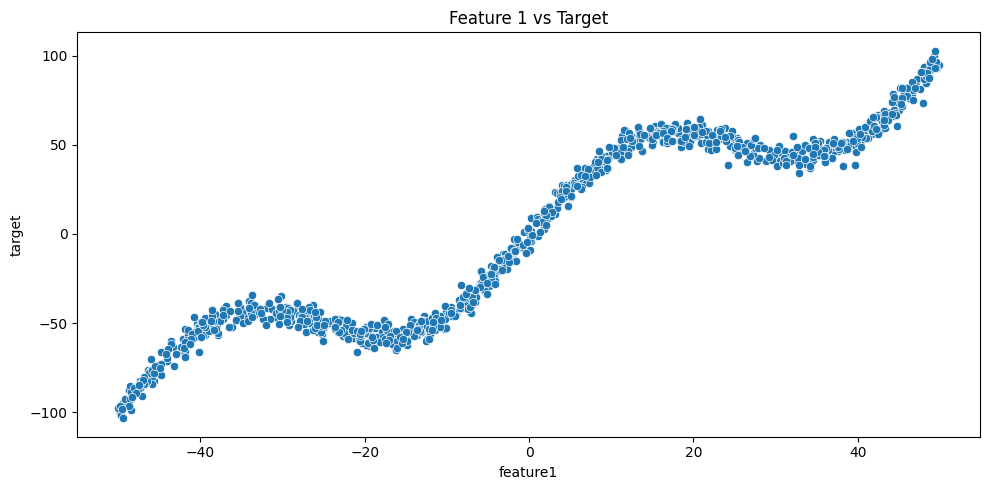

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1.000 titik x seragam di [-50, 50]
np.random.seed(123)
n_samples = 1000
X = np.random.uniform(-50, 50, (n_samples, 1))

# y = tren linear + gelombang sinus + noise Gaussian (sd = 4)
y = (2 * X[:, 0]
     + 27 * np.sin(X[:, 0] / 8)
     + np.random.normal(0, 4, n_samples))

data = pd.DataFrame(X, columns=['feature1'])
data['target'] = y

plt.figure(figsize=(10, 5))
sns.scatterplot(data=data, x='feature1', y='target')
plt.title('Feature 1 vs Target')
plt.tight_layout()
plt.show()

**Interpretasi output.** Plot sebar menunjukkan tren naik (kemiringan ≈ 2) dengan gelombang di atasnya: maksimum lokal di sekitar $x\approx-33$ dan $x\approx+18$ serta minimum lokal di sekitar $x\approx-18$ dan $x\approx+33$ (menyamakan turunan $2+\tfrac{27}{8}\cos(x/8)$ dengan nol menghasilkan $x\approx\pm17.6$ dan $\pm32.6$), sesuai dengan $\sin(x/8)$ yang berperiode $16\pi\approx50$. Sebaran vertikal di sekitar kurva kecil (sd *noise* = 4), sehingga model yang cukup fleksibel seharusnya mampu menjelaskan sebagian besar variansi.

In [12]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt

X = data[['feature1']]
y = data['target']

degrees = [1, 2, 3, 4, 5]
results = []

for degree in degrees:
    # Ekspansi x menjadi [1, x, ..., x^degree]
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)

    # Pembagian 80/20 yang sama untuk setiap derajat
    X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=123)

    # OLS pada fitur polinomial
    poly_model = LinearRegression()
    poly_model.fit(X_train, y_train)

    y_pred = poly_model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Degree': degree,
        'MSE': mse,
        'R2': r2
    })

results_df = pd.DataFrame(results)
print("\nModel Performance Metrics:")
print(results_df.to_string(index=False))


Model Performance Metrics:
 Degree        MSE       R2
      1 317.005037 0.891135
      2 316.818454 0.891199
      3 268.477397 0.907800
      4 268.230101 0.907885
      5  48.316167 0.983407


**Interpretasi output.** Kinerja uji membaik **berpasangan**, persis seperti yang diprediksi argumen fungsi ganjil: derajat 1 → 2 hampir tidak mengubah apa pun (MSE 317.0 → 316.8, $R^2$ 0.8911 → 0.8912), begitu pula derajat 3 → 4 (268.5 → 268.2, $R^2$ 0.9078 → 0.9079), sedangkan setiap derajat *ganjil* baru membawa peningkatan nyata. Derajat 5 adalah lonjakan besar: **MSE 48.3, $R^2 = 0.983$**. Variansi *noise* yang tidak dapat direduksi adalah $4^2=16$, sehingga derajat 5 masih sekitar 3× batas *noise* dan menyisakan sebagian struktur yang belum terjelaskan.

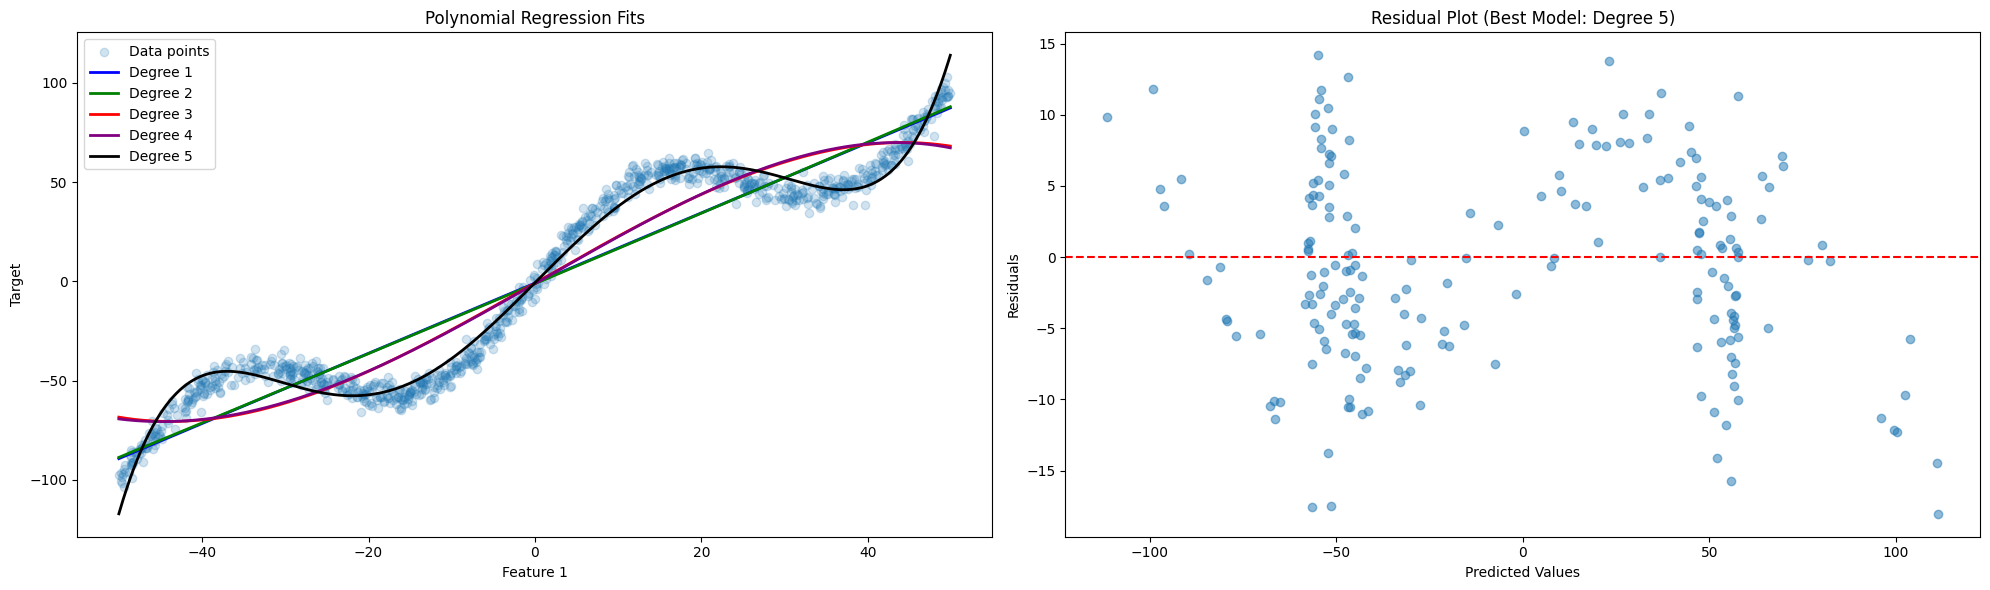

In [13]:
# Kiri: kurva fit untuk setiap derajat; kanan: residual derajat terbaik
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))

ax1.scatter(X['feature1'], y, alpha=0.2, label='Data points')

# Grid nilai x yang rapat untuk kurva yang halus
X_plot = np.linspace(X['feature1'].min(), X['feature1'].max(), 1000).reshape(-1, 1)

colors = ['blue', 'green', 'red', 'purple', 'black']
for degree, color in zip(degrees, colors):
    poly = PolynomialFeatures(degree=degree)
    X_plot_poly = poly.fit_transform(X_plot)

    # Fit ulang pada seluruh data untuk kurva visual
    model = LinearRegression()
    model.fit(poly.fit_transform(X), y)
    y_plot = model.predict(X_plot_poly)

    ax1.plot(X_plot, y_plot, label=f'Degree {degree}', color=color, linewidth=2)

ax1.set_xlabel('Feature 1')
ax1.set_ylabel('Target')
ax1.set_title('Polynomial Regression Fits')
ax1.legend(loc='upper left')

# Pilih derajat dengan R^2 uji tertinggi dan fit ulang pada bagian data latih
best_degree = results_df.loc[results_df['R2'].idxmax(), 'Degree']
best_poly = PolynomialFeatures(degree=best_degree)
X_poly_best = best_poly.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_poly_best, y, test_size=0.2, random_state=123)

best_model = LinearRegression()
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
residuals = y_test - y_pred

ax2.scatter(y_pred, residuals, alpha=0.5)
ax2.axhline(y=0, color='r', linestyle='--')
ax2.set_xlabel('Predicted Values')
ax2.set_ylabel('Residuals')
ax2.set_title(f'Residual Plot (Best Model: Degree {best_degree})')

plt.tight_layout()
plt.show()

**Interpretasi output.**

* **Panel kiri:** kurva derajat 1 (biru) dan derajat 2 (hijau) saling menimpa sebagai satu garis lurus, dan derajat 3 (merah) tersembunyi di bawah derajat 4 (ungu), berupa kurva S yang landai. Hanya kurva **derajat 5** (hitam) yang mengikuti gelombang dan memotong data di dekat kedua tonjolan. Kurva ini juga melengkung tajam di batas ($x=\pm50$), perilaku tepi yang khas pada polinomial.
* **Panel kanan:** residual model derajat 5 pada 200 titik uji berkisar kira-kira dari −18 hingga +14 dan **tidak tanpa struktur**. Residual membentuk pita vertikal yang padat di sekitar nilai prediksi kira-kira −50 dan +50 (bagian gelombang yang datar), dan titik-titik dengan prediksi yang mirip memiliki residual yang mirip. Pola ini berarti sebagian struktur gelombang sinus masih belum dimodelkan, sesuai dengan MSE (48.3) yang jauh di atas batas *noise* (16).

**Interpolasi spline.** Alih-alih satu polinomial global, buku selanjutnya mem-fit spline kubik sepotong-sepotong dengan 3, 5, dan 7 knot.

/Users/taraanrp/Telkom/Machine Learning/Scikit-learn Cookbook (O’Reilly)./.venv/lib/python3.13/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SplineTransformer was fitted with feature names
  warnings.warn(
/Users/taraanrp/Telkom/Machine Learning/Scikit-learn Cookbook (O’Reilly)./.venv/lib/python3.13/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SplineTransformer was fitted with feature names
  warnings.warn(
/Users/taraanrp/Telkom/Machine Learning/Scikit-learn Cookbook (O’Reilly)./.venv/lib/python3.13/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SplineTransformer was fitted with feature names
  warnings.warn(


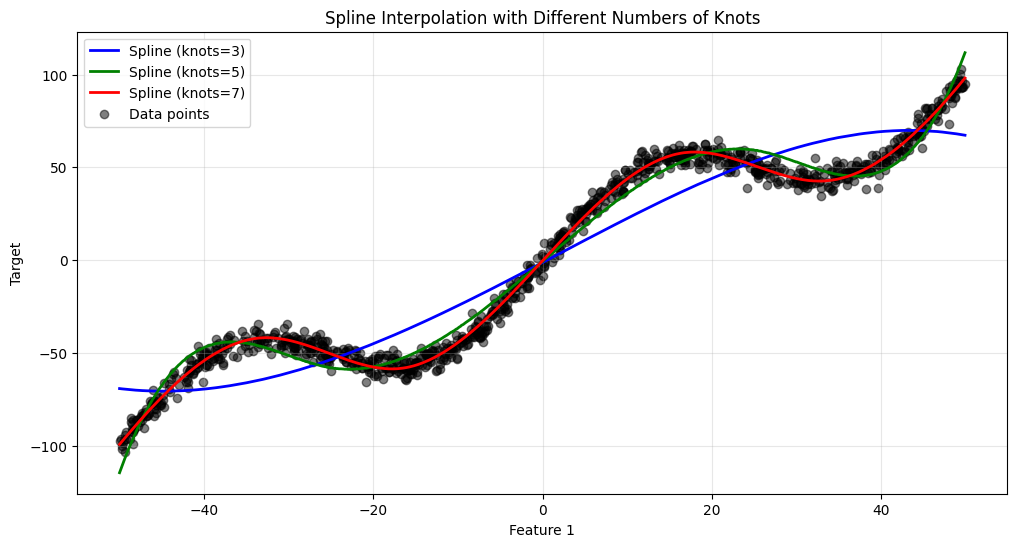

,Number of Knots,MSE,R-squared
0,3,274.251426,0.904658
1,5,55.365011,0.980753
2,7,15.500684,0.994611


In [14]:
from sklearn.preprocessing import SplineTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

n_knots = [3, 5, 7]
plt.figure(figsize=(12, 6))

mse_scores = []
r2_scores = []

for n_knot, color in zip(n_knots, colors[:len(n_knots)]):
    # Basis B-spline kubik diikuti OLS
    spline = SplineTransformer(n_knots=n_knot, degree=3)
    model = make_pipeline(spline, LinearRegression())
    model.fit(X, y)

    # Kurva halus pada grid, dan prediksi in-sample untuk metrik
    y_pred = model.predict(X_plot)
    y_pred_train = model.predict(X)

    # Metrik dihitung pada data yang sama dengan data untuk fitting model
    mse = mean_squared_error(y, y_pred_train)
    r2 = r2_score(y, y_pred_train)
    mse_scores.append(mse)
    r2_scores.append(r2)

    plt.plot(X_plot, y_pred,
             label=f'Spline (knots={n_knot})',
             color=color,
             linewidth=2)

plt.scatter(X, y, color='black', alpha=0.5, label='Data points')
plt.xlabel('Feature 1')
plt.ylabel('Target')
plt.title('Spline Interpolation with Different Numbers of Knots')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

metrics_df = pd.DataFrame({
    'Number of Knots': n_knots,
    'MSE': mse_scores,
    'R-squared': r2_scores
})
display(metrics_df)

> **Catatan:** `UserWarning: X does not have valid feature names, but SplineTransformer was fitted with feature names` muncul karena *pipeline* di-fit pada DataFrame `X`, tetapi kurva halus diprediksi dari grid NumPy `X_plot`. Nilai dan urutan kolomnya cocok, sehingga kurvanya benar. Peringatan dibiarkan agar kode buku tidak berubah.

In [15]:
# Jumlah fungsi basis spline yang dibuat untuk setiap jumlah knot (tambahan)
for k in n_knots:
    print(f"n_knots={k}: {SplineTransformer(n_knots=k, degree=3).fit(X).n_features_out_} fungsi basis")

n_knots=3: 5 fungsi basis
n_knots=5: 7 fungsi basis
n_knots=7: 9 fungsi basis


**Interpretasi output.**

* **3 knot** (5 fungsi basis, biru) menghasilkan bentuk S halus yang hampir identik dengan polinomial derajat 3/4: MSE 274.3, $R^2 = 0.905$.
* **5 knot** (7 fungsi basis, hijau) sudah mengikuti gelombang dengan cermat: MSE 55.4, $R^2 = 0.981$. Kurvanya melampaui data di tepi kanan ($x\to50$), tempat potongan terakhir hanya dibatasi sedikit titik.
* **7 knot** (9 fungsi basis, merah) menelusuri data hampir sempurna: **MSE 15.5, $R^2 = 0.995$**. Itu pada dasarnya batas *noise* ($\sigma^2=16$), hanya dengan 9 koefisien, lebih sedikit dari yang dibutuhkan polinomial derajat 5 untuk fit yang jauh lebih buruk (48.3).
* Metrik ini bersifat **in-sample** (model dinilai pada data yang dipakai untuk melatihnya), sehingga sedikit optimis dibandingkan hasil polinomial pada data yang disisihkan. Dengan hanya 9 parameter untuk 1.000 titik, selisihnya seharusnya kecil.

### Poin Penting
* Ekspansi basis memungkinkan model linear mem-fit kurva: model tetap linear dalam koefisiennya.
* Untuk target ganjil, hanya derajat polinomial ganjil yang membantu (1≈2, 3≈4). Derajat 5 mencapai $R^2$ 0.983 tetapi residualnya masih menunjukkan struktur.
* Spline kubik dengan 7 knot (9 fungsi basis) mencapai MSE 15.5 ≈ variansi *noise*, lebih baik dan lebih stabil daripada polinomial global.
* Lebih banyak knot atau derajat yang lebih tinggi menambah fleksibilitas sekaligus variansi, jadi pilihlah lewat validasi, bukan lewat $R^2$ in-sample.

## Resep 5.5 — Latihan Praktis Model Linear dan Regularisasi

**Tujuan.** Mem-fit regresi Ridge, Lasso, dan ElasticNet pada tiga dataset sintetis 1-D baru, melaporkan MSE/$R^2$ latih dan uji, serta memvisualisasikan setiap garis hasil fit.

### Teori

Ketiga latihan memakai ulang penalti yang didefinisikan di Resep 5.2–5.3 pada masalah 1-D sederhana, sehingga efeknya mudah dilihat:

* **Latihan 1 (Ridge):** data mengikuti **parabola**, $y = 0.5x^2 + x + \varepsilon$, tetapi modelnya garis lurus. Regularisasi mengendalikan variansi, bukan bias, sehingga tidak ada `alpha` yang bisa membuat garis mengikuti kurva. Latihan ini adalah pelajaran tentang *kesalahan spesifikasi model*.
* **Latihan 2 (Lasso):** $y = 4 + 3x + \varepsilon$ memang linear. Dengan `alpha=0.1`, penalti L1 mengecilkan kemiringan ke arah nol (*soft-thresholding* sebesar $\alpha$), sehingga estimasinya sedikit bias.
* **Latihan 3 (ElasticNet):** $y = 3x + 2\sin x + \varepsilon$ didominasi suku linear. Suku sinus adalah penyimpangan periodik kecil yang tidak dapat ditangkap garis tetapi hampir tidak memengaruhi $R^2$ karena trennya sangat kuat.

Metrik latih dan uji dibandingkan untuk mendiagnosis *underfitting* vs *overfitting*: nilai yang mirip berarti model bergeneralisasi sebaik kecocokannya pada data latih, sedangkan latih ≫ uji berarti *overfitting*. **$R^2$ uji yang negatif** berarti model memprediksi data uji lebih buruk daripada konstanta rata-rata data uji.

### Kode — Latihan 1: Mengimplementasikan Regresi Ridge

Training Metrics:
MSE: 1.9780
R²: 0.6575

Test Metrics:
MSE: 2.5628
R²: -0.0360


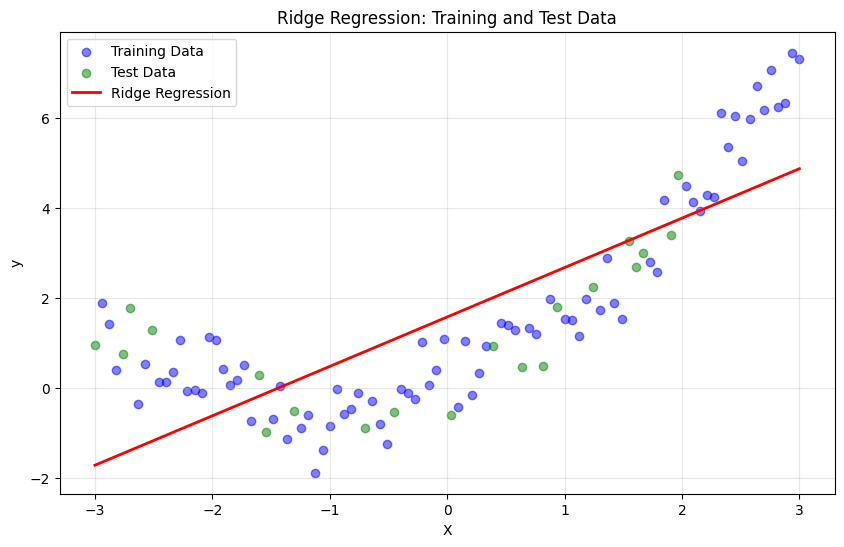

In [16]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Data kuadratik: y = 0.5 x^2 + x + noise
np.random.seed(123)
X = np.linspace(-3, 3, 100).reshape(-1, 1)
y = 0.5 * X.ravel()**2 + X.ravel() + np.random.normal(0, 0.5, 100)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

# Garis lurus dengan penalti L2 pada kemiringannya
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)

y_pred_train = ridge.predict(X_train)
y_pred_test = ridge.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

print("Training Metrics:")
print(f"MSE: {mse_train:.4f}")
print(f"R²: {r2_train:.4f}")
print("\nTest Metrics:")
print(f"MSE: {mse_test:.4f}")
print(f"R²: {r2_test:.4f}")

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Training Data')
plt.scatter(X_test, y_test, color='green', alpha=0.5, label='Test Data')

# Evaluasi garis hasil fit pada nilai x yang terurut
X_plot = np.sort(X, axis=0)
y_plot = ridge.predict(X_plot)
plt.plot(X_plot, y_plot, color='red', linewidth=2, label='Ridge Regression')

plt.xlabel('X')
plt.ylabel('y')
plt.title('Ridge Regression: Training and Test Data')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [17]:
# Mengapa R^2 uji negatif? Bandingkan variansi target di kedua bagian data (tambahan)
print("kemiringan / intersep hasil fit:", ridge.coef_.round(3), round(ridge.intercept_, 3))
print("variansi y_train:", round(y_train.var(), 3), "| variansi y_test:", round(y_test.var(), 3))

kemiringan / intersep hasil fit: [1.099] 1.572
variansi y_train: 5.775 | variansi y_test: 2.474


**Interpretasi output.** Plot langsung menunjukkan masalahnya: data membentuk parabola berbentuk U, dan garis Ridge merah (kemiringan ≈ 1,10, intersep ≈ 1,57) memotongnya lurus. Garis terlalu tinggi di tengah dan terlalu rendah di kedua ujung. $R^2$ latih hanya **0.6575** (MSE 1.978), dan $R^2$ uji **−0.0360** (MSE 2.563). Nilai negatif ini sebagian merupakan sifat pembagian data tertentu ini: target uji kebetulan jauh kurang bervariasi (variansi 2,47) dibanding target latih (5,77), sehingga penyebut $R^2$ kecil dan galat sistematis garis tampak lebih buruk daripada memprediksi rata-rata data uji. Solusinya adalah model yang lebih baik (misalnya `PolynomialFeatures(degree=2)` sebelum Ridge), bukan `alpha` yang berbeda.

### Kode — Latihan 2: Mengimplementasikan Regresi Lasso

Training Metrics:
MSE: 0.2631
R²: 0.8814

Test Metrics:
MSE: 0.4239
R²: 0.8419


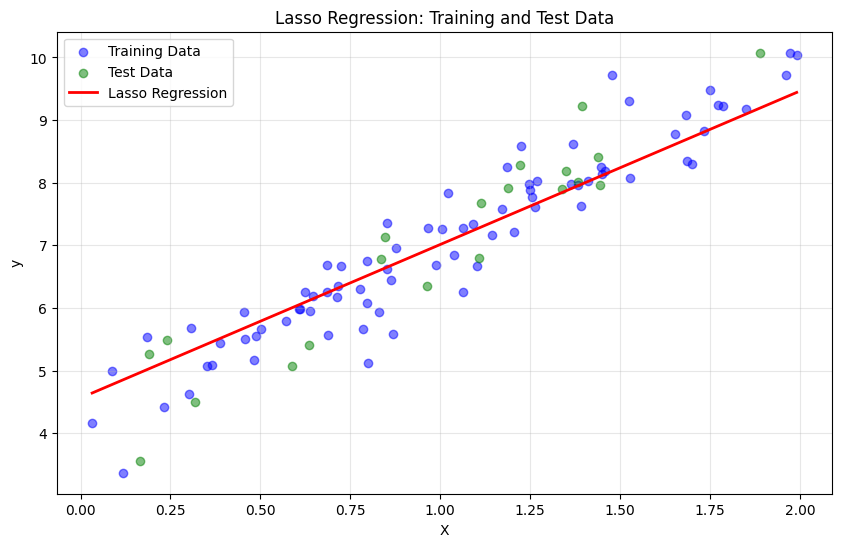

In [18]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Data yang benar-benar linear: y = 4 + 3x + noise, x di [0, 2)
np.random.seed(123)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1) * 0.5

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

# Garis dengan penalti L1
lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)

y_pred_train = lasso.predict(X_train)
y_pred_test = lasso.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

print("Training Metrics:")
print(f"MSE: {mse_train:.4f}")
print(f"R²: {r2_train:.4f}")
print("\nTest Metrics:")
print(f"MSE: {mse_test:.4f}")
print(f"R²: {r2_test:.4f}")

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Training Data')
plt.scatter(X_test, y_test, color='green', alpha=0.5, label='Test Data')

X_plot = np.sort(X, axis=0)
y_plot = lasso.predict(X_plot)
plt.plot(X_plot, y_plot, color='red', linewidth=2, label='Lasso Regression')

plt.xlabel('X')
plt.ylabel('y')
plt.title('Lasso Regression: Training and Test Data')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [19]:
# Pengecilan: bandingkan kemiringan Lasso dengan kemiringan OLS tanpa penalti (kemiringan sebenarnya = 3) (tambahan)
from sklearn.linear_model import LinearRegression
ols_slope = LinearRegression().fit(X_train, y_train).coef_.ravel()[0]
print(f"Kemiringan Lasso = {lasso.coef_[0]:.3f}, intersep = {lasso.intercept_[0]:.3f} | kemiringan OLS = {ols_slope:.3f}")

Kemiringan Lasso = 2.451, intersep = 4.562 | kemiringan OLS = 2.861


**Interpretasi output.** Garis Lasso mengikuti data linear dengan baik: $R^2$ latih **0.8814** (MSE 0.263) dan $R^2$ uji **0.8419** (MSE 0.424), dengan selisih latih/uji yang kecil. Pengecekan tambahan menunjukkan kerja penalti L1: kemiringan Lasso **2.451**, jelas di bawah kemiringan OLS tanpa penalti 2.861 pada data latih yang sama (nilai sebenarnya 3), dengan intersep naik menjadi 4.562 sebagai kompensasi. Dengan hanya satu fitur dan data yang cukup banyak, pengecilan ini menambah bias tanpa manfaat variansi. Di sini `alpha=0.1` memang terlalu kuat, dan `alpha` sebaiknya di-*tuning* dengan *cross-validation*.

### Kode — Latihan 3: Mengimplementasikan Regresi ElasticNet

Training Metrics:
MSE: 4.6771
R²: 0.9849

Test Metrics:
MSE: 4.0393
R²: 0.9867


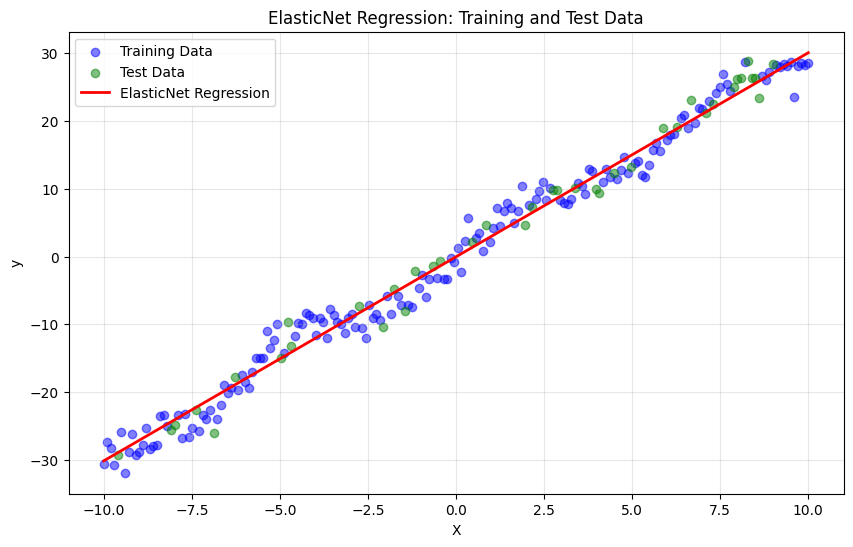

In [20]:
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Tren linear kuat ditambah goyangan sinus kecil: y = 3x + 2 sin(x) + noise
np.random.seed(123)
X = np.linspace(-10, 10, 200).reshape(-1, 1)
y = 3*X + np.sin(X) * 2 + np.random.normal(0, 1.5, X.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

# Penalti campuran L1/L2
elastic_net = ElasticNet(alpha=0.1, l1_ratio=0.5)
elastic_net.fit(X_train, y_train)

y_pred_train = elastic_net.predict(X_train)
y_pred_test = elastic_net.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

print("Training Metrics:")
print(f"MSE: {mse_train:.4f}")
print(f"R²: {r2_train:.4f}")
print("\nTest Metrics:")
print(f"MSE: {mse_test:.4f}")
print(f"R²: {r2_test:.4f}")

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Training Data')
plt.scatter(X_test, y_test, color='green', alpha=0.5, label='Test Data')

X_plot = np.sort(X, axis=0)
y_plot = elastic_net.predict(X_plot)
plt.plot(X_plot, y_plot, color='red', linewidth=2, label='ElasticNet Regression')

plt.xlabel('X')
plt.ylabel('y')
plt.title('ElasticNet Regression: Training and Test Data')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Interpretasi output.** ElasticNet menjelaskan **98,5 %** variansi data latih dan **98,7 %** variansi data uji (MSE 4.68 / 4.04). Skor uji bahkan sedikit lebih baik daripada skor latih, sehingga tidak ada *overfitting*. Dengan rentang target sekitar ±30, penalti `alpha=0.1` tergolong ringan dibanding kemiringan ≈ 3. Galat yang tersisa (MSE ≈ 4) menggabungkan variansi *noise* ($1.5^2=2.25$) dan goyangan $2\sin x$ (rata-rata kuadratnya $2^2/2=2$) yang tidak dapat diikuti garis lurus. Plot menunjukkan data berosilasi lembut di sekitar garis merah.

### Poin Penting
* Regularisasi tidak dapat memperbaiki bentuk model yang salah: Ridge pada parabola menghasilkan $R^2$ latih 0,66 dan $R^2$ uji negatif.
* Lasso jelas mengecilkan koefisien (kemiringan 2,45 vs OLS 2,86). Pada masalah sederhana yang terdefinisi dengan baik, pengecilan itu murni bias.
* Ketika bentuk model linear memang tepat (Latihan 3), penalti ElasticNet yang ringan memberi fit hampir sempurna ($R^2$ ≈ 0,99) dan bergeneralisasi dengan baik.

## Ringkasan Bab

| Resep | Konsep | Kelas/fungsi sklearn utama | Poin penting |
|---|---|---|---|
| 5.1 Pengantar Model Linear | *Ordinary least squares*, MSE dan $R^2$, efek kolinearitas | `LinearRegression`, `make_regression` | OLS *overfitting* (latih 0.356 vs uji 0.052). Dataset kehilangan 7 dari 10 fitur informatif, membatasi $R^2$ sekitar 0,21. |
| 5.2 Ridge dan Lasso | Penalti L2 vs L1, *trade-off* bias–variansi | `Ridge`, `Lasso` | Ridge ($R^2$ 0.09) menangani kolinearitas lebih baik daripada Lasso yang lemah (0.06). `alpha` bergantung pada skala. |
| 5.3 ElasticNet | Penalti campuran L1/L2, jalur koefisien | `ElasticNet` | Koefisien mengecil dari ±200.000 ke ~0 seiring bertambahnya $\alpha$. ElasticNet($\alpha=1$, $\rho=0.5$) terbaik ($R^2$ 0.15). |
| 5.4 Regresi Polinomial & Spline | Ekspansi basis; polinomial global vs B-spline lokal | `PolynomialFeatures`, `SplineTransformer`, `make_pipeline` | Target ganjil → hanya derajat ganjil yang membantu (derajat 5: $R^2$ 0.983). Spline 7 knot mencapai batas *noise* (MSE 15.5). |
| 5.5 Latihan Praktis | Diagnostik latih vs uji untuk garis berpenalti | `Ridge`, `Lasso`, `ElasticNet` | Penalti tidak dapat memperbaiki salah spesifikasi. Pengecilan Lasso terlihat jelas. ElasticNet mem-fit target hampir linear dengan $R^2$ ≈ 0,99. |

**Kaitan dengan Bab 6.** Semua model di sini memprediksi bilangan kontinu. Bab 6 mempertahankan prediktor linear yang sama, $\beta_0+\mathbf{x}^\top\boldsymbol\beta$, tetapi melewatkannya ke **fungsi logistik (sigmoid)** untuk memperoleh peluang kelas, sehingga regresi linear berubah menjadi **regresi logistik** untuk klasifikasi. Penalti L1 dan L2 dari bab ini muncul kembali di sana dalam bentuk parameter `C` ($C = 1/\text{kekuatan regularisasi}$).

## Referensi

* Sukup, J. (2025). *scikit-learn Cookbook, Third Edition*. Packt Publishing. Bab 5.
* Repositori kode resmi: <https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition>
* scikit-learn User Guide — Linear Models (OLS, Ridge, Lasso, ElasticNet): <https://scikit-learn.org/1.5/modules/linear_model.html>
* scikit-learn API — `make_regression`: <https://scikit-learn.org/1.5/modules/generated/sklearn.datasets.make_regression.html>
* scikit-learn User Guide — Polynomial features dan spline transformer: <https://scikit-learn.org/1.5/modules/preprocessing.html#generating-polynomial-features>
* scikit-learn User Guide — Regression metrics (MSE, $R^2$): <https://scikit-learn.org/1.5/modules/model_evaluation.html#regression-metrics>
* Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (edisi ke-2), Bab 3 dan 5. Springer.